In [3]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

from pathlib import Path

In [4]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3
EPOCHS = 50

In [5]:
DATA_DIR = Path("PLD_3_Classes_256")

TRAIN_DIR = DATA_DIR / "Training"
VAL_DIR = DATA_DIR / "Validation"
TEST_DIR = DATA_DIR / "Testing"

# Image configuration
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=123
)

# Extract the actual disease classes
class_names = train_ds.class_names

print("Disease classes:", class_names)

# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_names=class_names
)

# Load test data
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_names=class_names
)

print("\nTraining classes:", train_ds.class_names)
print("Validation classes:", val_ds.class_names)
print("Testing classes:", test_ds.class_names)

print("\nNumber of disease classes:", len(class_names))

Found 3251 files belonging to 3 classes.
Disease classes: ['Early_Blight', 'Healthy', 'Late_Blight']
Found 416 files belonging to 3 classes.
Found 405 files belonging to 3 classes.

Training classes: ['Early_Blight', 'Healthy', 'Late_Blight']
Validation classes: ['Early_Blight', 'Healthy', 'Late_Blight']
Testing classes: ['Early_Blight', 'Healthy', 'Late_Blight']

Number of disease classes: 3


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [7]:
class_names = dataset.class_names

NameError: name 'dataset' is not defined

In [ ]:
class_names

['Testing', 'Training', 'Validation']

In [ ]:
len(dataset)

128

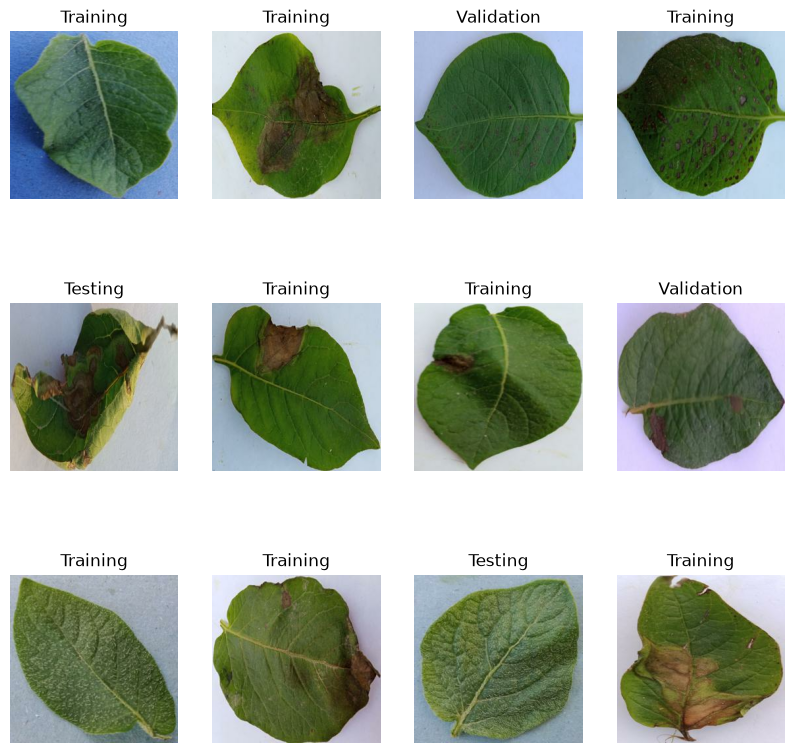

In [ ]:
plt.figure(figsize=(10,10))
for image_batch, label_batch in dataset.take(1):
  for i in range(12):
    ax = plt.subplot(3,4,i+1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.title(class_names[label_batch[i]])
    plt.axis("off")

In [ ]:
len(dataset)

128

80% ==> training
20% ==> 10% validation, 10% test

In [ ]:
train_size = 0.8
len(dataset)*train_size

102.4

In [ ]:
train_ds = dataset.take(54)
len(train_ds)

54

In [ ]:
test_ds=dataset.skip(54)
len(test_ds)

74

In [ ]:
val_size = 0.1
len(dataset)*val_size

12.8

len(dataset)

In [ ]:
val_ds = test_ds.take(6)
len(val_ds)

6

In [ ]:
test_ds = test_ds.skip(6)
len(test_ds)

68

In [ ]:
def get_dataset_partitions_tf(ds,train_split = 0.8,val_split = 0.1,test_split = 0.1,shuffle = True, shuffle_size = 10000 ):
    assert (train_split + test_split + val_split) == 1
    ds_size = len(ds)
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed = 12)
        
    train_size = int(train_split * ds_size)
    val_size = int(val_split *ds_size)
    train_ds = ds.take(train_size)

    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    return train_ds,val_ds,test_ds

In [ ]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [ ]:
len(train_ds)

102

In [ ]:
len(val_ds)

12

In [ ]:
len(test_ds)

14

In [ ]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)

In [ ]:

resize_and_rescale = tf.keras.Sequential([
  layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0 / 255)
])

In [ ]:
data_augumentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

In [ ]:


input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    layers.Input(shape=input_shape),

    resize_and_rescale,
    data_augumentation,  # Use the exact variable name you defined

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30


102/102 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.7938 - loss: 0.6640 - val_accuracy: 0.7995 - val_loss: 0.6533
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.7938 - loss: 0.6634 - val_accuracy: 0.7995 - val_loss: 0.6420
Epoch 3/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.7938 - loss: 0.6567 - val_accuracy: 0.7995 - val_loss: 0.6418
Epoch 4/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 101s 993ms/step - accuracy: 0.7938 - loss: 0.6555 - val_accuracy: 0.7995 - val_loss: 0.6431
Epoch 5/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.7938 - loss: 0.6559 - val_accuracy: 0.7995 - val_loss: 0.6495
Epoch 6/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 95s 922ms/step - accuracy: 0.7938 - loss: 0.6538 - val_accuracy: 0.7995 - val_loss: 0.6418
Epoch 7/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 87s 852ms/step - accuracy: 0.7938 - loss: 0.6540 - val_accuracy: 0.7995 - val_loss: 0.6416
Epoch 8/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 79s 778ms/step - accuracy: 0.7938 - loss: 0.6549 - val_accura

In [ ]:
 scores = model.evaluate(test_ds)

14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 342ms/step - accuracy: 0.8103 - loss: 0.6177


In [ ]:
scores

[0.6176810264587402, 0.8102678656578064]

In [ ]:
history

In [ ]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 102}

In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss  = history.history['loss']
val_loss = history.history['val_loss']

In [ ]:

import matplotlib.pyplot as plt

# Extract metrics from the current training run
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

# Use the actual number of completed epochs
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(15, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(alpha=0.3)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


NameError: name 'history' is not defined

first image to predict
actual label: Training
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step
predicted label: Training


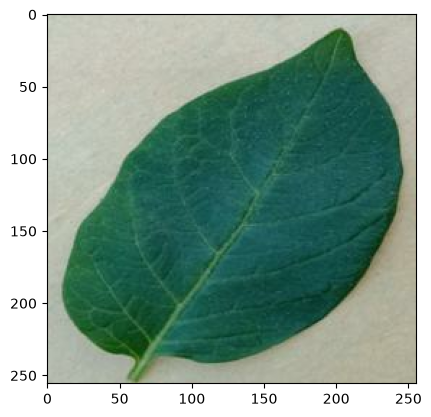

In [ ]:

import numpy as np
def predict(model, img):
    # Resize the image to match the training dimensions
    img = img.resize((IMAGE_SIZE, IMAGE_SIZE))

    # Convert image to an array
    img_array = tf.keras.utils.img_to_array(img)

    # Add a batch dimension
    img_array = tf.expand_dims(img_array, axis=0)

    # Generate predictions
    predictions = model.predict(img_array, verbose=0)

    # Identify the predicted class
    predicted_index = int(np.argmax(predictions[0]))
    predicted_class = class_names[predicted_index]

    # Calculate the predicted class score
    confidence = float(np.max(predictions[0]) * 100)

    return predicted_class, confidence

In [ ]:
from PIL import Image
from pathlib import Path

image_path = (
    Path("PLD_3_Classes_256")
    / "Testing"
    / "Early_Blight"
)

image_file = next(image_path.glob("*"))

img = Image.open(image_file).convert("RGB")

predicted_class, confidence = predict(model, img)

print("Image:", image_file.name)
print("Predicted disease:", predicted_class)
print(f"Model confidence score: {confidence:.2f}%")

NameError: name 'predict' is not defined

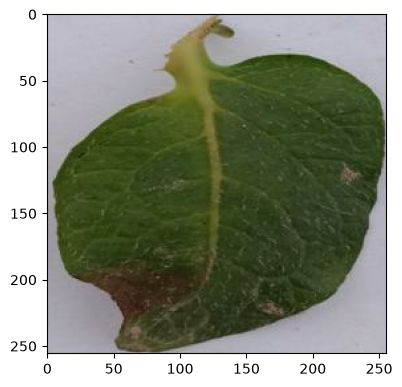

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(15, 15))

for images, labels in test_ds.take(1):

    num_images = min(9, len(images))

    for i in range(num_images):

        ax = plt.subplot(3, 3, i + 1)

        image = images[i].numpy()

        # Display the image
        plt.imshow(image.astype("uint8"))

        # Predict disease class
        predicted_class, confidence = predict(model, image)

        # Convert the actual label to an integer
        actual_label = int(labels[i].numpy())

        actual_class = class_names[actual_label]

        # Display prediction details
        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2f}%",
            fontsize=10
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import tensorflow as tf

DATA_DIR = Path("PLD_3_Classes_256")

print("Dataset exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for folder in DATA_DIR.iterdir():
        if folder.is_dir():
            print(f"\nFolder: {folder.name}")

            for subfolder in folder.iterdir():
                if subfolder.is_dir():
                    image_count = sum(
                        1 for file in subfolder.rglob("*")
                        if file.suffix.lower() in {
                            ".jpg", ".jpeg", ".png", ".bmp"
                        }
                    )

                    print(
                        f"  Class: {subfolder.name} | "
                        f"Images: {image_count}"
                    )

Dataset exists: True

Folder: Testing
  Class: Early_Blight | Images: 162
  Class: Healthy | Images: 102
  Class: Late_Blight | Images: 141

Folder: Training
  Class: Early_Blight | Images: 1303
  Class: Healthy | Images: 816
  Class: Late_Blight | Images: 1132

Folder: Validation
  Class: Early_Blight | Images: 163
  Class: Healthy | Images: 102
  Class: Late_Blight | Images: 151


In [ ]:
print("Class names:", class_names)
print("Model output shape:", model.output_shape)
print("Model input shape:", model.input_shape)

Class names: ['Testing', 'Training', 'Validation']
Model output shape: (None, 3)
Model input shape: (None, 256, 256, 3)


In [ ]:

model.summary()

print("\nFinal layer:")
print(model.layers[-1])

print("\nFinal layer activation:")
print(model.layers[-1].get_config())


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 551,243 (2.10 MB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 367,496 (1.40 MB)


Final layer:
<Dense name=dense_3, built=True>

Final layer activation:
{'name': 'dense_3', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 3, 'activation': 'softmax', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None, 'input_axes': None, 'output_axes': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}


In [ ]:
import json

with open("models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")

Class names saved successfully!


In [ ]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

model.save("models/potato_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
print("Class names:", class_names)

print("\nTraining metrics:")
print("Accuracy:", history.history["accuracy"])
print("Validation accuracy:", history.history["val_accuracy"])

print("\nFinal model output layer:")
model.summary()

NameError: name 'class_names' is not defined